ESTIMATION SAMPLE: 2700 obs | 125 countries | 2001-2023
Controls (t-1): ['lnGDPpc_lag1', 'GOV_lag1', 'RULE_lag1', 'Trade_lag1', 'GDPGrowth_lag1', 'GFCF_lag1', 'UrbanGrowth_lag1', 'LFPR_lag1']


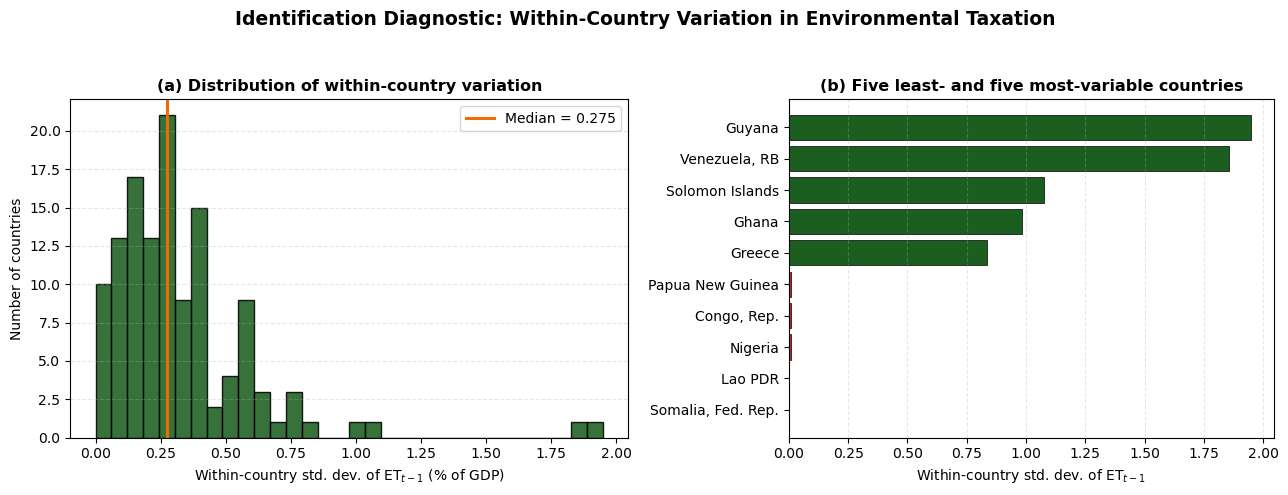

Countries with sd < 0.05: 8 of 125

SPEC A - NAIVE TWO-WAY FE OLS (linear controls)
theta = 0.0452  se = 0.0227  95% CI [0.0008, 0.0896]

SPEC B - DML POOLED (no fixed effects)
DoubleML: theta = 0.0210  se = 0.0137
Cluster-robust final stage: theta = 0.0210  se = 0.0267  95% CI [-0.0314, 0.0733]

SPEC C - DML TWO-WAY FE (HEADLINE)
DoubleML: theta = 0.0338  se = 0.0093
Cluster-robust final stage: theta = 0.0338  se = 0.0161  95% CI [0.0023, 0.0654]


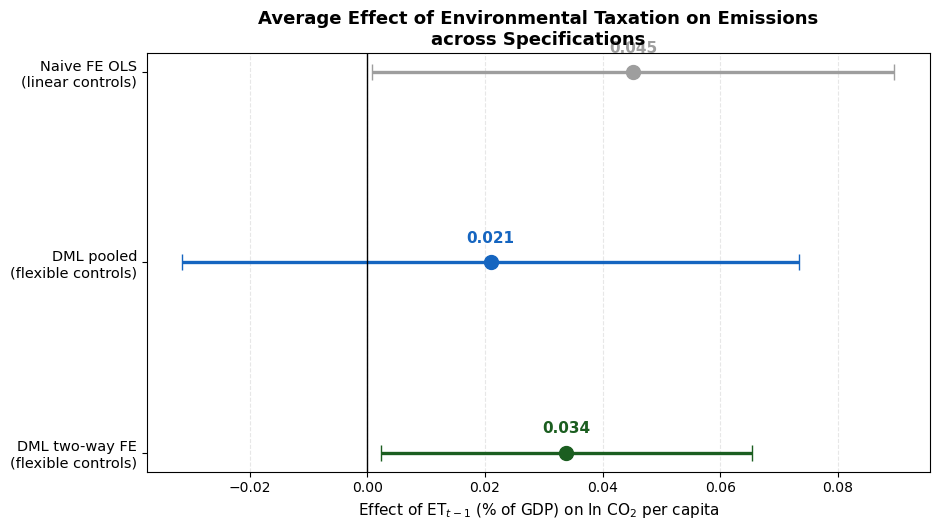

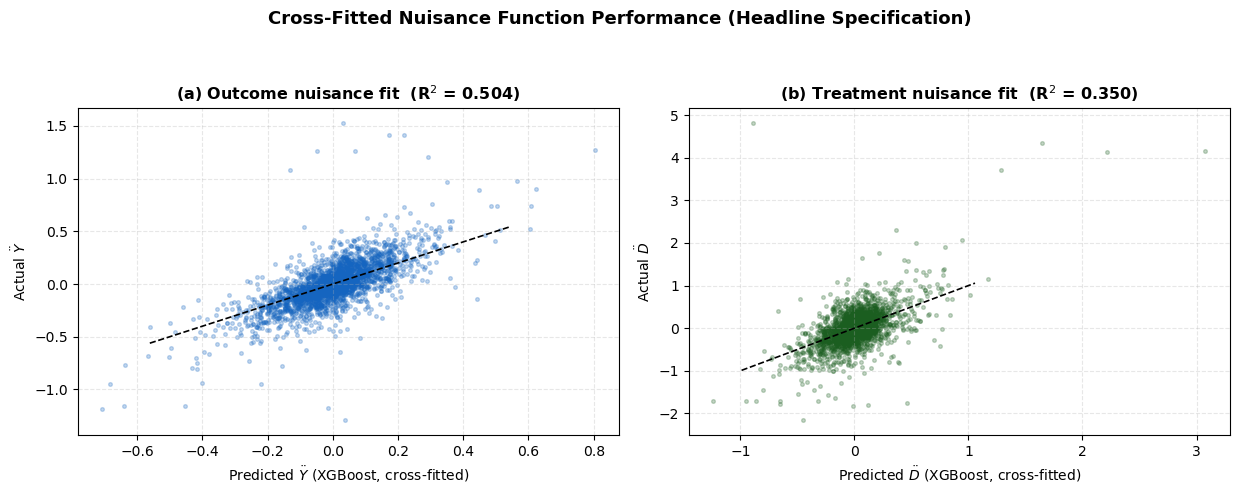


       Specification             Fixed effects     Controls  theta  SE (cluster)  CI low  CI high    N  Countries
Naive two-way FE OLS            Country + Year  Linear, t-1 0.0452        0.0227  0.0008   0.0896 2700        125
          DML pooled                      None XGBoost, t-1 0.0210        0.0267 -0.0314   0.0733 2700        125
      DML two-way FE Country + Year (demeaned) XGBoost, t-1 0.0338        0.0161  0.0023   0.0654 2700        125

Saved: C:\Users\PMLS\Desktop\Causal ML for CO2 and ET\Tables\Table_Average_Effects.xlsx
Figures in: C:\Users\PMLS\Desktop\Causal ML for CO2 and ET\Figures
Estimation sample and residuals saved for Script 2.


In [1]:
# ============================================================
# PAPER 2 - SCRIPT 1: AVERAGE EFFECTS (Sections 3.2-3.3)
#   Spec A: Naive two-way FE OLS (linear controls) - benchmark
#   Spec B: DML pooled (flexible controls, no FE)
#   Spec C: DML two-way FE (HEADLINE, Clarke-Polselli style)
#   Figures: F1 within-variation diagnostic
#            F2 coefficient staircase
#            F3 nuisance-fit quality panel
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from xgboost import XGBRegressor
from doubleml import DoubleMLData, DoubleMLPLR

# ============================================================
# 0. PATHS AND DATA
# ============================================================

DIRECTORY  = r"C:\Users\PMLS\Desktop\Causal ML for CO2 and ET"
FILE_NAME  = "Causal_CO2_ET_Data_File.xlsx"
FIGURE_DIR = os.path.join(DIRECTORY, "Figures")
TABLE_DIR  = os.path.join(DIRECTORY, "Tables")
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

df = pd.read_excel(os.path.join(DIRECTORY, FILE_NAME), sheet_name="Panel_Format")
df.columns = df.columns.astype(str).str.strip()

# ---- identify columns ----
country_col, year_col, co2_col = None, None, None
for col in df.columns:
    cl = col.lower()
    if cl == "country":                       country_col = col
    if cl == "year":                          year_col = col
    if "co2" in cl or "co₂" in cl:
        if co2_col is None:                   co2_col = col

gdp_ln_lag = "ln GDP per capita (t-1)"       # created in the merge
assert all([country_col, year_col, co2_col]), "key columns missing"
assert gdp_ln_lag in df.columns, "lagged lnGDPpc column missing"

df = df.replace("..", np.nan)
for c in df.columns:
    if c != country_col:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# ---- short codes ----
code_map = {}
for name in df.columns:
    n = name.lower()
    if "government effectiveness" in n:                 code_map[name] = "GOV"
    elif "rule of law" in n:                            code_map[name] = "RULE"
    elif "urban" in n:                                  code_map[name] = "UrbanGrowth"
    elif "labor force" in n or "labour force" in n:     code_map[name] = "LFPR"
    elif "gross fixed" in n:                            code_map[name] = "GFCF"
    elif "gdp growth" in n:                             code_map[name] = "GDPGrowth"
    elif n.startswith("trade"):                         code_map[name] = "Trade"
    elif n.strip() == "et" or ("environ" in n and "tax" in n): code_map[name] = "ET"
df = df.rename(columns=code_map)

# ============================================================
# 1. VARIABLE CONSTRUCTION (outcome t, treatment & controls t-1)
# ============================================================

df = df.sort_values([country_col, year_col]).reset_index(drop=True)
df["lnCO2"] = np.log(df[co2_col].where(df[co2_col] > 0))
df["ET_lag1"] = df.groupby(country_col)["ET"].shift(1)

base_controls = ["GOV", "RULE", "Trade", "GDPGrowth", "GFCF", "UrbanGrowth", "LFPR"]
lag_controls = []
for c in base_controls:
    lc = c + "_lag1"
    df[lc] = df.groupby(country_col)[c].shift(1)
    lag_controls.append(lc)
df = df.rename(columns={gdp_ln_lag: "lnGDPpc_lag1"})
lag_controls = ["lnGDPpc_lag1"] + lag_controls

d = df.dropna(subset=["lnCO2", "ET_lag1", "lnGDPpc_lag1"]).copy()
for c in lag_controls:
    d[c] = d[c].fillna(d[c].median())
d = d.dropna(subset=["lnCO2", "ET_lag1"] + lag_controls).reset_index(drop=True)

n_obs, n_countries = len(d), d[country_col].nunique()
print(f"ESTIMATION SAMPLE: {n_obs} obs | {n_countries} countries | "
      f"{int(d[year_col].min())}-{int(d[year_col].max())}")
print("Controls (t-1):", lag_controls)

# ============================================================
# FIGURE F1 - identification diagnostic: within-country ET variation
# ============================================================

within_sd = d.groupby(country_col)["ET_lag1"].std().dropna().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.15, 1]})

axes[0].hist(within_sd, bins=32, color="#1B5E20", edgecolor="black", alpha=0.88)
axes[0].axvline(within_sd.median(), color="#EF6C00", lw=2.2,
                label=f"Median = {within_sd.median():.3f}")
axes[0].set_xlabel("Within-country std. dev. of ET$_{t-1}$ (% of GDP)")
axes[0].set_ylabel("Number of countries")
axes[0].set_title("(a) Distribution of within-country variation",
                  fontsize=11.5, fontweight="bold")
axes[0].legend(); axes[0].grid(axis="y", ls="--", alpha=0.3)

demo = pd.concat([within_sd.tail(5), within_sd.head(5)]).sort_values()
colors = ["#C62828"]*5 + ["#1B5E20"]*5
axes[1].barh(demo.index, demo.values, color=colors, edgecolor="black", lw=0.5)
axes[1].set_xlabel("Within-country std. dev. of ET$_{t-1}$")
axes[1].set_title("(b) Five least- and five most-variable countries",
                  fontsize=11.5, fontweight="bold")
axes[1].grid(axis="x", ls="--", alpha=0.3)

fig.suptitle("Identification Diagnostic: Within-Country Variation in Environmental Taxation",
             fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(os.path.join(FIGURE_DIR, "F1_Within_Variation.png"), dpi=300,
            bbox_inches="tight")
plt.show()
print(f"Countries with sd < 0.05: {(within_sd < 0.05).sum()} of {len(within_sd)}")

# ============================================================
# 2. SPEC A - NAIVE TWO-WAY FE OLS (benchmark)
#    linear controls + country and year dummies
# ============================================================

X_naive = pd.get_dummies(
    d[["ET_lag1"] + lag_controls + [country_col, year_col]],
    columns=[country_col, year_col], drop_first=True, dtype=float)
X_naive = sm.add_constant(X_naive)

ols_fe = sm.OLS(d["lnCO2"], X_naive).fit(
    cov_type="cluster", cov_kwds={"groups": d[country_col]})
A_coef = ols_fe.params["ET_lag1"]
A_lo, A_hi = ols_fe.conf_int().loc["ET_lag1"]
A_se = ols_fe.bse["ET_lag1"]
print("\n" + "="*62)
print("SPEC A - NAIVE TWO-WAY FE OLS (linear controls)")
print("="*62)
print(f"theta = {A_coef:.4f}  se = {A_se:.4f}  95% CI [{A_lo:.4f}, {A_hi:.4f}]")

# ============================================================
# 3. DML SETUP
# ============================================================

def make_learner():
    return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8,
                        random_state=42, n_jobs=-1)

def run_dml(frame, y, t, xcols, label, cluster):
    dml_data = DoubleMLData(frame[[y, t] + xcols].copy(),
                            y_col=y, d_cols=t, x_cols=xcols)
    try:
        mdl = DoubleMLPLR(dml_data, ml_l=make_learner(), ml_m=make_learner(),
                          n_folds=5)
    except TypeError:
        mdl = DoubleMLPLR(dml_data, ml_g=make_learner(), ml_m=make_learner(),
                          n_folds=5)
    mdl.fit(store_predictions=True)
    s = mdl.summary
    coef, se = s["coef"].iloc[0], s["std err"].iloc[0]

    # cluster-robust correction of the final residual regression
    preds = mdl.predictions
    l_hat = preds["ml_l"][:, 0, 0] if "ml_l" in preds else preds["ml_g"][:, 0, 0]
    m_hat = preds["ml_m"][:, 0, 0]
    v = frame[t].values - m_hat                     # treatment residual
    u = frame[y].values - l_hat                     # outcome residual
    fin = sm.OLS(u, v).fit(cov_type="cluster",
                           cov_kwds={"groups": frame[cluster].values})
    c_coef, c_se = fin.params[0], fin.bse[0]
    c_lo, c_hi = fin.conf_int()[0]

    print("\n" + "="*62)
    print(f"{label}")
    print("="*62)
    print(f"DoubleML: theta = {coef:.4f}  se = {se:.4f}")
    print(f"Cluster-robust final stage: theta = {c_coef:.4f}  se = {c_se:.4f}  "
          f"95% CI [{c_lo:.4f}, {c_hi:.4f}]")
    return {"coef": c_coef, "se": c_se, "lo": c_lo, "hi": c_hi,
            "u": u, "v": v, "y": frame[y].values, "t": frame[t].values,
            "l_hat": l_hat, "m_hat": m_hat}

np.random.seed(42)

# ---- SPEC B: pooled DML ----
resB = run_dml(d, "lnCO2", "ET_lag1", lag_controls,
               "SPEC B - DML POOLED (no fixed effects)", country_col)

# ---- SPEC C: two-way FE DML (headline) ----
def two_way_demean(s, frame):
    return (s - s.groupby(frame[country_col]).transform("mean")
              - s.groupby(frame[year_col]).transform("mean") + s.mean())

d["lnCO2_dm"]   = two_way_demean(d["lnCO2"], d)
d["ET_lag1_dm"] = two_way_demean(d["ET_lag1"], d)

resC = run_dml(d, "lnCO2_dm", "ET_lag1_dm", lag_controls,
               "SPEC C - DML TWO-WAY FE (HEADLINE)", country_col)

# ============================================================
# FIGURE F2 - the coefficient staircase
# ============================================================

names = ["Naive FE OLS\n(linear controls)",
         "DML pooled\n(flexible controls)",
         "DML two-way FE\n(flexible controls)"]
specs = [(A_coef, A_lo, A_hi, "#9E9E9E"),
         (resB["coef"], resB["lo"], resB["hi"], "#1565C0"),
         (resC["coef"], resC["lo"], resC["hi"], "#1B5E20")]

fig, ax = plt.subplots(figsize=(9.5, 5.4))
ypos = np.arange(3)[::-1]
for yp, (c, lo, hi, col), nm in zip(ypos, specs, names):
    ax.errorbar(c, yp, xerr=[[c-lo], [hi-c]], fmt="o", color=col,
                capsize=6, markersize=10, lw=2.4)
    ax.annotate(f"{c:.3f}", (c, yp), textcoords="offset points",
                xytext=(0, 14), ha="center", fontsize=11,
                fontweight="bold", color=col)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(ypos); ax.set_yticklabels(names, fontsize=10.5)
ax.set_xlabel("Effect of ET$_{t-1}$ (% of GDP) on ln CO$_2$ per capita",
              fontsize=11)
ax.set_title("Average Effect of Environmental Taxation on Emissions\nacross Specifications",
             fontsize=13, fontweight="bold")
ax.grid(axis="x", ls="--", alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "F2_Coefficient_Staircase.png"), dpi=300,
            bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE F3 - nuisance-fit quality (referee-facing diagnostic)
# ============================================================

def r2(actual, pred):
    ssr = np.sum((actual - pred)**2)
    sst = np.sum((actual - actual.mean())**2)
    return 1 - ssr/sst

r2_l = r2(d["lnCO2_dm"].values, resC["l_hat"])
r2_m = r2(d["ET_lag1_dm"].values, resC["m_hat"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
axes[0].scatter(resC["l_hat"], d["lnCO2_dm"], s=7, alpha=0.25, color="#1565C0")
lims = np.percentile(d["lnCO2_dm"], [1, 99])
axes[0].plot(lims, lims, color="black", lw=1.2, ls="--")
axes[0].set_xlabel("Predicted $\\ddot{Y}$ (XGBoost, cross-fitted)")
axes[0].set_ylabel("Actual $\\ddot{Y}$")
axes[0].set_title(f"(a) Outcome nuisance fit  (R$^2$ = {r2_l:.3f})",
                  fontsize=11.5, fontweight="bold")
axes[0].grid(ls="--", alpha=0.3)

axes[1].scatter(resC["m_hat"], d["ET_lag1_dm"], s=7, alpha=0.25, color="#1B5E20")
lims = np.percentile(d["ET_lag1_dm"], [1, 99])
axes[1].plot(lims, lims, color="black", lw=1.2, ls="--")
axes[1].set_xlabel("Predicted $\\ddot{D}$ (XGBoost, cross-fitted)")
axes[1].set_ylabel("Actual $\\ddot{D}$")
axes[1].set_title(f"(b) Treatment nuisance fit  (R$^2$ = {r2_m:.3f})",
                  fontsize=11.5, fontweight="bold")
axes[1].grid(ls="--", alpha=0.3)

fig.suptitle("Cross-Fitted Nuisance Function Performance (Headline Specification)",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(os.path.join(FIGURE_DIR, "F3_Nuisance_Fit.png"), dpi=300,
            bbox_inches="tight")
plt.show()

# ============================================================
# 4. EXPORT ESTIMATES TABLE
# ============================================================

tab = pd.DataFrame({
    "Specification": ["Naive two-way FE OLS", "DML pooled", "DML two-way FE"],
    "Fixed effects": ["Country + Year", "None", "Country + Year (demeaned)"],
    "Controls": ["Linear, t-1", "XGBoost, t-1", "XGBoost, t-1"],
    "theta": [A_coef, resB["coef"], resC["coef"]],
    "SE (cluster)": [A_se, resB["se"], resC["se"]],
    "CI low": [A_lo, resB["lo"], resC["lo"]],
    "CI high": [A_hi, resB["hi"], resC["hi"]],
    "N": [n_obs]*3, "Countries": [n_countries]*3
})
out_tab = os.path.join(TABLE_DIR, "Table_Average_Effects.xlsx")
tab.round(4).to_excel(out_tab, index=False)
print("\n" + tab.round(4).to_string(index=False))
print(f"\nSaved: {out_tab}")
print("Figures in:", FIGURE_DIR)

# keep residuals for Script 2 (causal forest / GATES / CLAN)
d.to_pickle(os.path.join(DIRECTORY, "estimation_sample.pkl"))
np.save(os.path.join(DIRECTORY, "residuals_u.npy"), resC["u"])
np.save(os.path.join(DIRECTORY, "residuals_v.npy"), resC["v"])
print("Estimation sample and residuals saved for Script 2.")

Loaded: 2700 obs, 125 countries
Moderators: ['lnGDPpc_lag1', 'GOV_lag1', 'UrbanGrowth_lag1', 'Trade_lag1']

Fitting full-sample causal forest (1,000 trees)...
Mean CATE (should approximate theta): 0.0512
CATE 5th-95th percentile: [-0.0305, 0.2939]
Share with CI entirely > 0: 21.3%
Share with CI entirely < 0: 0.9%


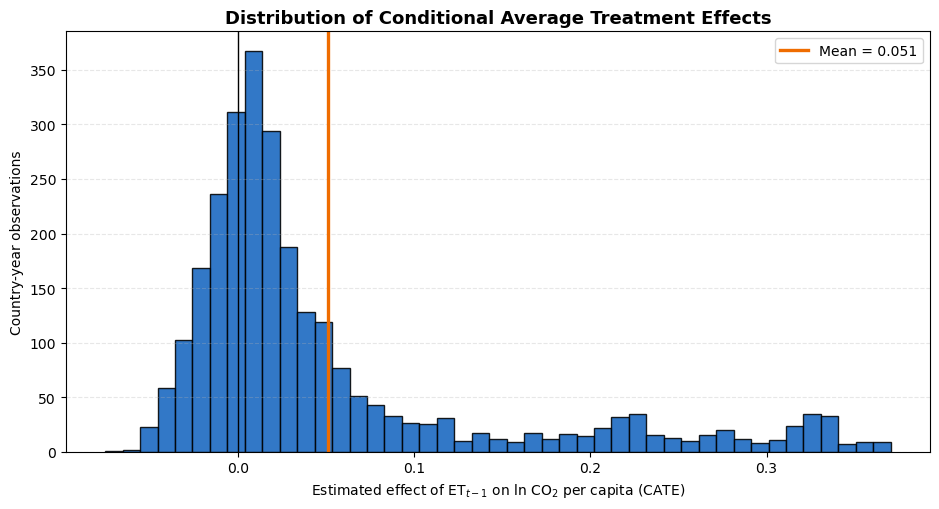

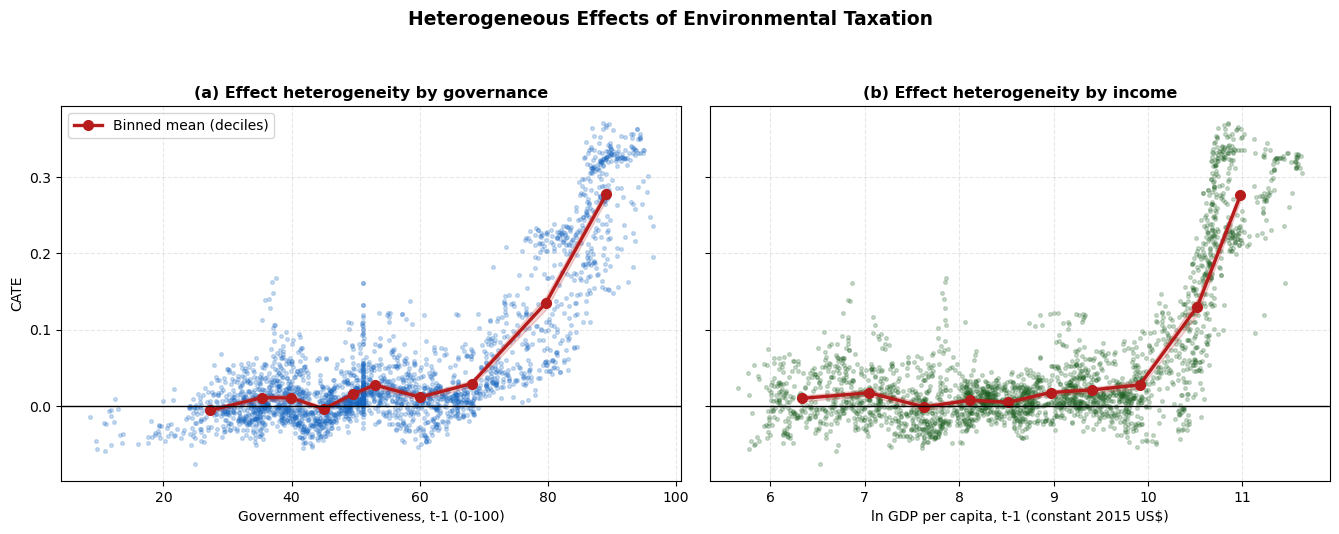


Running 50 sample splits (this takes a few minutes)...

BLP (median over splits; adjusted 95% CIs)
beta1 (ATE):            0.0455  CI [-0.0027, 0.0914]
beta2 (heterogeneity):  0.8430  CI [0.1997, 1.4243]
median p-value (beta2 = 0): 0.0018

GATES (median over splits; adjusted 95% CIs)
Group 1 (least->most affected): gamma =   0.0273   CI [-0.0554, 0.1106]
Group 2 (least->most affected): gamma =   0.0122   CI [-0.0731, 0.0922]
Group 3 (least->most affected): gamma =  -0.0027   CI [-0.0765, 0.0722]
Group 4 (least->most affected): gamma =   0.0024   CI [-0.0509, 0.0744]
Group 5 (least->most affected): gamma =   0.2164   CI [0.0796, 0.3524]

gamma_5 - gamma_1 = 0.1846  CI [0.0066, 0.3640]  median p = 0.0197

CLAN (median over splits; adjusted 95% CIs)
                  mean_G5  mean_G1    diff      lo      hi
moderator                                                 
lnGDPpc_lag1       10.521    7.965   2.617   2.473   2.766
GOV_lag1           81.622   42.054  40.729  38.543  42.834
UrbanG

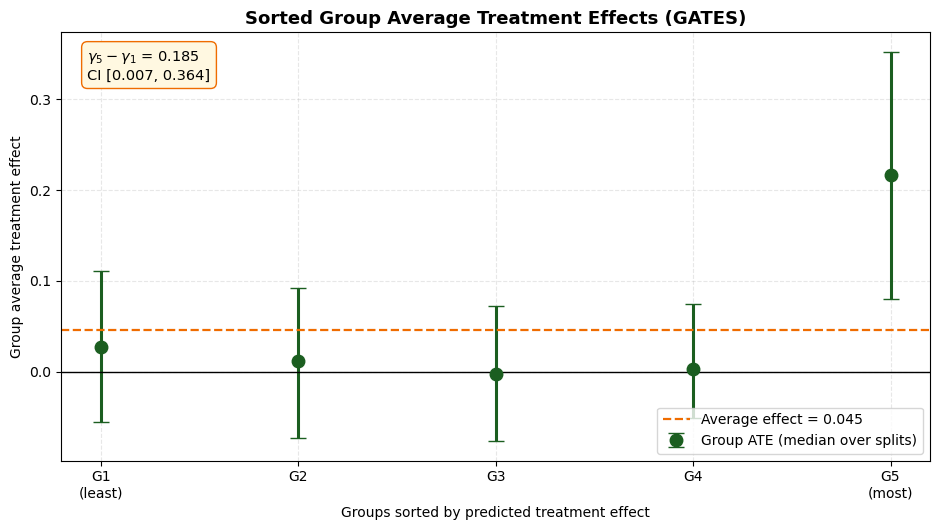


All heterogeneity outputs saved. Figures F4-F6 in Figures/,
tables in Tables/Table_Heterogeneity.xlsx, CATEs in cate_full.npy


In [2]:
# ============================================================
# PAPER 2 - SCRIPT 2: HETEROGENEITY (Sections 3.4-3.5)
#   Part 1: Causal forest on DML residuals -> CATEs + figures
#   Part 2: BLP / GATES / CLAN with median-over-splits inference
#   Figures: F4 CATE distribution
#            F5 CATE vs governance and income (2 panels)
#            F6 GATES ladder
#   Tables:  BLP, GATES, CLAN (Excel)
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# econml's raw GRF forest (takes pre-residualised inputs directly)
try:
    from econml.grf import CausalForest
except ImportError:
    raise ImportError("Please: pip install econml \"numpy<2\"")

# ============================================================
# 0. LOAD SCRIPT-1 OUTPUTS
# ============================================================

DIRECTORY  = r"C:\Users\PMLS\Desktop\Causal ML for CO2 and ET"
FIGURE_DIR = os.path.join(DIRECTORY, "Figures")
TABLE_DIR  = os.path.join(DIRECTORY, "Tables")

d = pd.read_pickle(os.path.join(DIRECTORY, "estimation_sample.pkl"))
u = np.load(os.path.join(DIRECTORY, "residuals_u.npy"))   # outcome residual
v = np.load(os.path.join(DIRECTORY, "residuals_v.npy"))   # treatment residual

country_col = [c for c in d.columns if c.lower() == "country"][0]

moderators = ["lnGDPpc_lag1", "GOV_lag1", "UrbanGrowth_lag1", "Trade_lag1"]
X = d[moderators].values
countries = d[country_col].values
print(f"Loaded: {len(d)} obs, {d[country_col].nunique()} countries")
print("Moderators:", moderators)

RNG = np.random.RandomState(42)

# ============================================================
# PART 1 - FULL-SAMPLE CAUSAL FOREST (for CATE figures)
# ============================================================

print("\nFitting full-sample causal forest (1,000 trees)...")
cf_full = CausalForest(n_estimators=1000, min_samples_leaf=10,
                       max_samples=0.5, honest=True, random_state=42)
cf_full.fit(X, v, u)                       # (X, T-residual, Y-residual)
cate = cf_full.predict(X).ravel()
lb, ub = cf_full.predict_interval(X, alpha=0.05)
lb, ub = lb.ravel(), ub.ravel()

print(f"Mean CATE (should approximate theta): {cate.mean():.4f}")
print(f"CATE 5th-95th percentile: [{np.percentile(cate,5):.4f}, "
      f"{np.percentile(cate,95):.4f}]")
print(f"Share with CI entirely > 0: {(lb > 0).mean():.1%}")
print(f"Share with CI entirely < 0: {(ub < 0).mean():.1%}")

# ---- FIGURE F4: CATE distribution ----
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.hist(cate, bins=45, color="#1565C0", edgecolor="black", alpha=0.88)
ax.axvline(0, color="black", lw=1)
ax.axvline(cate.mean(), color="#EF6C00", lw=2.4,
           label=f"Mean = {cate.mean():.3f}")
ax.set_xlabel("Estimated effect of ET$_{t-1}$ on ln CO$_2$ per capita (CATE)")
ax.set_ylabel("Country-year observations")
ax.set_title("Distribution of Conditional Average Treatment Effects",
             fontsize=13, fontweight="bold")
ax.legend(); ax.grid(axis="y", ls="--", alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "F4_CATE_Distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ---- FIGURE F5: CATE vs governance and income ----
def binned_curve(ax, xvals, n_bins=10):
    edges = np.quantile(xvals, np.linspace(0, 1, n_bins + 1))
    ids = np.digitize(xvals, edges[1:-1])
    bx, bm, blo, bhi = [], [], [], []
    for b in range(n_bins):
        m = ids == b
        if m.sum() > 5:
            bx.append(xvals[m].mean()); mu = cate[m].mean()
            se = cate[m].std() / np.sqrt(m.sum())
            bm.append(mu); blo.append(mu - 1.96*se); bhi.append(mu + 1.96*se)
    ax.plot(bx, bm, "o-", color="#B71C1C", lw=2.4, ms=7,
            label="Binned mean (deciles)")
    ax.fill_between(bx, blo, bhi, color="#B71C1C", alpha=0.18)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharey=True)

gov = d["GOV_lag1"].values
axes[0].scatter(gov, cate, s=7, alpha=0.22, color="#1565C0")
binned_curve(axes[0], gov)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("Government effectiveness, t-1 (0-100)")
axes[0].set_ylabel("CATE")
axes[0].set_title("(a) Effect heterogeneity by governance",
                  fontsize=11.5, fontweight="bold")
axes[0].legend(); axes[0].grid(ls="--", alpha=0.3)

inc = d["lnGDPpc_lag1"].values
axes[1].scatter(inc, cate, s=7, alpha=0.22, color="#1B5E20")
binned_curve(axes[1], inc)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("ln GDP per capita, t-1 (constant 2015 US$)")
axes[1].set_title("(b) Effect heterogeneity by income",
                  fontsize=11.5, fontweight="bold")
axes[1].grid(ls="--", alpha=0.3)

fig.suptitle("Heterogeneous Effects of Environmental Taxation",
             fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(os.path.join(FIGURE_DIR, "F5_CATE_vs_Gov_Income.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# PART 2 - BLP / GATES / CLAN, median over 50 country-level splits
#   (Chernozhukov, Demirer, Duflo & Fernandez-Val, 2025)
#   PLR adaptation: u = b1*v + b2*(S - S_bar)*v  (BLP)
#                   u = sum_k gamma_k * v * 1{G_k}  (GATES)
#   Cluster-robust SEs by country; per-split CIs at 97.5%,
#   medians of estimates and CI bounds reported.
# ============================================================

N_SPLITS = 50
K_GROUPS = 5
uniq_countries = np.unique(countries)

blp_rows, gates_rows, gap_rows, clan_rows = [], [], [], []

print(f"\nRunning {N_SPLITS} sample splits (this takes a few minutes)...")
for r in range(N_SPLITS):
    rs = np.random.RandomState(1000 + r)
    shuffled = rs.permutation(uniq_countries)
    half = len(shuffled) // 2
    A_set = set(shuffled[:half])                    # auxiliary (train forest)
    maskA = np.array([c in A_set for c in countries])
    maskB = ~maskA                                  # main (inference)

    cf_r = CausalForest(n_estimators=500, min_samples_leaf=10,
                        max_samples=0.5, honest=True,
                        random_state=2000 + r)
    cf_r.fit(X[maskA], v[maskA], u[maskA])
    S = cf_r.predict(X[maskB]).ravel()              # proxy on held-out half

    uB, vB, cB = u[maskB], v[maskB], countries[maskB]
    XB = X[maskB]

    # ---------- BLP ----------
    Z = np.column_stack([vB, (S - S.mean()) * vB])
    blp = sm.OLS(uB, Z).fit(cov_type="cluster", cov_kwds={"groups": cB})
    ci = blp.conf_int(alpha=0.025)                  # 97.5% per split
    blp_rows.append([blp.params[0], ci[0][0], ci[0][1],
                     blp.params[1], ci[1][0], ci[1][1],
                     blp.pvalues[1]])

    # ---------- GATES ----------
    qs = np.quantile(S, np.linspace(0, 1, K_GROUPS + 1))
    grp = np.clip(np.digitize(S, qs[1:-1]), 0, K_GROUPS - 1)
    G = np.zeros((maskB.sum(), K_GROUPS))
    for k in range(K_GROUPS):
        G[:, k] = (grp == k) * vB
    gts = sm.OLS(uB, G).fit(cov_type="cluster", cov_kwds={"groups": cB})
    ci = gts.conf_int(alpha=0.025)
    gates_rows.append(np.column_stack([gts.params, ci[:, 0], ci[:, 1]]))

    # gamma_5 - gamma_1
    L = np.zeros(K_GROUPS); L[-1], L[0] = 1, -1
    t_gap = gts.t_test(L)
    est = float(np.atleast_1d(t_gap.effect)[0])
    se  = float(np.atleast_1d(t_gap.sd)[0])
    zc  = 2.241                                     # 97.5% two-sided z
    gap_rows.append([est, est - zc*se, est + zc*se,
                     float(np.atleast_1d(t_gap.pvalue)[0])])

    # ---------- CLAN ----------
    top, bot = grp == K_GROUPS - 1, grp == 0
    for j, mod in enumerate(moderators):
        x_top, x_bot = XB[top, j], XB[bot, j]
        diff = x_top.mean() - x_bot.mean()
        se = np.sqrt(x_top.var(ddof=1)/len(x_top) +
                     x_bot.var(ddof=1)/len(x_bot))
        clan_rows.append([r, mod, x_top.mean(), x_bot.mean(), diff,
                          diff - zc*se, diff + zc*se])

# ---- aggregate: medians of estimates and CI bounds ----
blp_arr = np.array(blp_rows)
blp_med = np.median(blp_arr, axis=0)
print("\n" + "="*62)
print("BLP (median over splits; adjusted 95% CIs)")
print("="*62)
print(f"beta1 (ATE):            {blp_med[0]:.4f}  CI [{blp_med[1]:.4f}, {blp_med[2]:.4f}]")
print(f"beta2 (heterogeneity):  {blp_med[3]:.4f}  CI [{blp_med[4]:.4f}, {blp_med[5]:.4f}]")
print(f"median p-value (beta2 = 0): {np.median(blp_arr[:,6]):.4f}")

gates_arr = np.stack(gates_rows)                    # splits x K x 3
gates_med = np.median(gates_arr, axis=0)
gap_med = np.median(np.array(gap_rows), axis=0)
print("\n" + "="*62)
print("GATES (median over splits; adjusted 95% CIs)")
print("="*62)
for k in range(K_GROUPS):
    print(f"Group {k+1} (least->most affected): gamma = {gates_med[k,0]:>8.4f}"
          f"   CI [{gates_med[k,1]:.4f}, {gates_med[k,2]:.4f}]")
print(f"\ngamma_5 - gamma_1 = {gap_med[0]:.4f}  CI [{gap_med[1]:.4f}, "
      f"{gap_med[2]:.4f}]  median p = {gap_med[3]:.4f}")

clan_df = pd.DataFrame(clan_rows, columns=["split","moderator","mean_G5",
                                           "mean_G1","diff","lo","hi"])
clan_med = clan_df.groupby("moderator")[["mean_G5","mean_G1","diff","lo","hi"]].median()
clan_med = clan_med.loc[moderators]
print("\n" + "="*62)
print("CLAN (median over splits; adjusted 95% CIs)")
print("="*62)
print(clan_med.round(3).to_string())

# ============================================================
# FIGURE F6 - GATES ladder
# ============================================================

fig, ax = plt.subplots(figsize=(9.5, 5.4))
ks = np.arange(1, K_GROUPS + 1)
ax.errorbar(ks, gates_med[:, 0],
            yerr=[gates_med[:, 0] - gates_med[:, 1],
                  gates_med[:, 2] - gates_med[:, 0]],
            fmt="o", color="#1B5E20", capsize=6, ms=9, lw=2.2,
            label="Group ATE (median over splits)")
ax.axhline(0, color="black", lw=1)
ax.axhline(blp_med[0], color="#EF6C00", ls="--", lw=1.6,
           label=f"Average effect = {blp_med[0]:.3f}")
ax.set_xticks(ks)
ax.set_xticklabels([f"G{k}\n(least)" if k == 1 else
                    f"G{k}\n(most)" if k == K_GROUPS else f"G{k}"
                    for k in ks])
ax.set_xlabel("Groups sorted by predicted treatment effect")
ax.set_ylabel("Group average treatment effect")
ax.set_title("Sorted Group Average Treatment Effects (GATES)",
             fontsize=13, fontweight="bold")
ax.annotate(f"$\\gamma_5-\\gamma_1$ = {gap_med[0]:.3f}\n"
            f"CI [{gap_med[1]:.3f}, {gap_med[2]:.3f}]",
            xy=(0.03, 0.96), xycoords="axes fraction", va="top",
            fontsize=10.5,
            bbox=dict(boxstyle="round,pad=0.4", fc="#FFF8E1", ec="#EF6C00"))
ax.legend(loc="lower right"); ax.grid(ls="--", alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "F6_GATES_Ladder.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# EXPORT TABLES
# ============================================================

with pd.ExcelWriter(os.path.join(TABLE_DIR, "Table_Heterogeneity.xlsx")) as xw:
    pd.DataFrame({
        "Parameter": ["beta1 (ATE)", "beta2 (heterogeneity)"],
        "Estimate": [blp_med[0], blp_med[3]],
        "CI low": [blp_med[1], blp_med[4]],
        "CI high": [blp_med[2], blp_med[5]],
        "Median p (beta2=0)": [np.nan, np.median(blp_arr[:, 6])]
    }).round(4).to_excel(xw, sheet_name="BLP", index=False)

    pd.DataFrame({
        "Group": [f"G{k+1}" for k in range(K_GROUPS)] + ["G5 - G1"],
        "Estimate": list(gates_med[:, 0]) + [gap_med[0]],
        "CI low": list(gates_med[:, 1]) + [gap_med[1]],
        "CI high": list(gates_med[:, 2]) + [gap_med[2]],
    }).round(4).to_excel(xw, sheet_name="GATES", index=False)

    clan_med.round(4).to_excel(xw, sheet_name="CLAN")

np.save(os.path.join(DIRECTORY, "cate_full.npy"), cate)
print("\nAll heterogeneity outputs saved. Figures F4-F6 in Figures/,")
print("tables in Tables/Table_Heterogeneity.xlsx, CATEs in cate_full.npy")

Loaded estimation sample: 2700 obs, 125 countries

Running specifications (each takes ~1 min)...

R0 Headline: FE-DML, XGBoost                         theta = +0.0182  se = 0.0152  CI [-0.0116, +0.0481]  N = 2700
R1 Delta-treatment: change in ET (t-1)               theta = +0.0187  se = 0.0060  CI [+0.0069, +0.0306]  N = 2575
R2 First differences (year-demeaned)                 theta = +0.0040  se = 0.0049  CI [-0.0056, +0.0136]  N = 2575
R3 Nuisance learner: Random Forest                   theta = +0.0195  se = 0.0212  CI [-0.0220, +0.0610]  N = 2700
R4 Nuisance learner: LASSO                           theta = +0.0292  se = 0.0279  CI [-0.0255, +0.0839]  N = 2700
R5 Winsorised ET (1st/99th pct)                      theta = +0.0253  se = 0.0166  CI [-0.0072, +0.0578]  N = 2700
R6 Excl. 8 near-zero-variation countries             theta = +0.0190  se = 0.0144  CI [-0.0092, +0.0471]  N = 2529
R7 Excl. 5 most ET-volatile countries                theta = +0.0433  se = 0.0197  CI [+0.0047, +

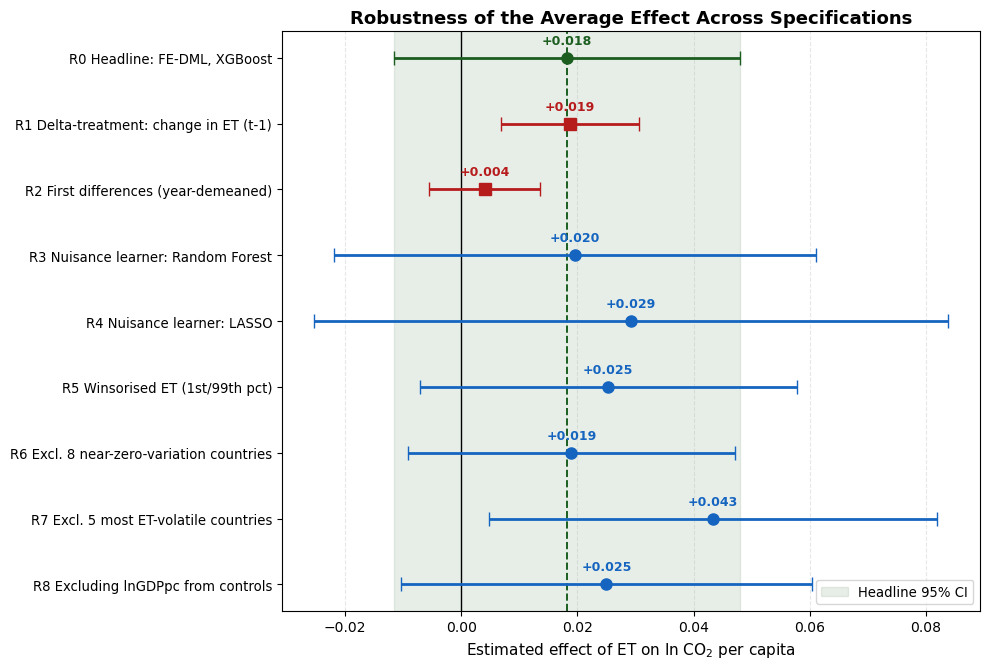

Saved: F7_Robustness.png


In [3]:
# ============================================================
# PAPER 2 - SCRIPT 3: ROBUSTNESS (Section 8)
#   R0  Headline (reference): DML two-way FE, XGBoost nuisances
#   R1  Delta-treatment: change in ET (mechanism test, Sec. 7)
#   R2  First-differenced outcome and treatment (FD vs FE)
#   R3  Nuisance learner: Random Forest
#   R4  Nuisance learner: LASSO
#   R5  Winsorised treatment (1st/99th pct)
#   R6  Excluding 8 near-zero ET-variation countries
#   R7  Excluding 5 most ET-volatile countries
#   R8  Excluding lnGDPpc from controls
#   Output: Tables/Table_Robustness.xlsx + Figures/F7_Robustness.png
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from doubleml import DoubleMLData, DoubleMLPLR

# ============================================================
# 0. LOAD
# ============================================================

DIRECTORY  = r"C:\Users\PMLS\Desktop\Causal ML for CO2 and ET"
FIGURE_DIR = os.path.join(DIRECTORY, "Figures")
TABLE_DIR  = os.path.join(DIRECTORY, "Tables")

d0 = pd.read_pickle(os.path.join(DIRECTORY, "estimation_sample.pkl"))
country_col = [c for c in d0.columns if c.lower() == "country"][0]
year_col    = [c for c in d0.columns if c.lower() == "year"][0]

lag_controls = ["lnGDPpc_lag1", "GOV_lag1", "RULE_lag1", "Trade_lag1",
                "GDPGrowth_lag1", "GFCF_lag1", "UrbanGrowth_lag1", "LFPR_lag1"]
print(f"Loaded estimation sample: {len(d0)} obs, "
      f"{d0[country_col].nunique()} countries")

# ============================================================
# 1. MACHINERY
# ============================================================

def two_way_demean(s, frame):
    return (s - s.groupby(frame[country_col]).transform("mean")
              - s.groupby(frame[year_col]).transform("mean") + s.mean())

def xgb_learner():
    return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8,
                        random_state=42, n_jobs=-1)

def rf_learner():
    return RandomForestRegressor(n_estimators=500, min_samples_leaf=5,
                                 max_features="sqrt", random_state=42,
                                 n_jobs=-1)

def lasso_learner():
    return make_pipeline(StandardScaler(),
                         LassoCV(cv=5, random_state=42, n_jobs=-1))

def run_spec(frame, y, t, xcols, learner_fn, label):
    """DML PLR with cluster-robust final stage; returns dict of results."""
    np.random.seed(42)
    dml_data = DoubleMLData(frame[[y, t] + xcols].copy(),
                            y_col=y, d_cols=t, x_cols=xcols)
    try:
        mdl = DoubleMLPLR(dml_data, ml_l=learner_fn(), ml_m=learner_fn(),
                          n_folds=5)
    except TypeError:
        mdl = DoubleMLPLR(dml_data, ml_g=learner_fn(), ml_m=learner_fn(),
                          n_folds=5)
    mdl.fit(store_predictions=True)
    preds = mdl.predictions
    l_hat = preds["ml_l"][:, 0, 0] if "ml_l" in preds else preds["ml_g"][:, 0, 0]
    m_hat = preds["ml_m"][:, 0, 0]
    u = frame[y].values - l_hat
    v = frame[t].values - m_hat
    fin = sm.OLS(u, v).fit(cov_type="cluster",
                           cov_kwds={"groups": frame[country_col].values})
    lo, hi = fin.conf_int()[0]
    res = {"label": label, "coef": fin.params[0], "se": fin.bse[0],
           "lo": lo, "hi": hi, "N": len(frame),
           "countries": frame[country_col].nunique()}
    print(f"{label:52s} theta = {res['coef']:+.4f}  "
          f"se = {res['se']:.4f}  CI [{lo:+.4f}, {hi:+.4f}]  N = {res['N']}")
    return res

results = []
print("\nRunning specifications (each takes ~1 min)...\n")

# ============================================================
# R0. HEADLINE (re-run for the table)
# ============================================================

d = d0.copy()
d["Y_dm"] = two_way_demean(d["lnCO2"], d)
d["T_dm"] = two_way_demean(d["ET_lag1"], d)
results.append(run_spec(d, "Y_dm", "T_dm", lag_controls, xgb_learner,
                        "R0 Headline: FE-DML, XGBoost"))

# ============================================================
# R1. DELTA-TREATMENT (mechanism test for Section 7)
#     Treatment = year-over-year change in ET, lagged
# ============================================================

d = d0.copy()
d = d.sort_values([country_col, year_col])
d["dET_lag1"] = d.groupby(country_col)["ET_lag1"].diff()
d1 = d.dropna(subset=["dET_lag1"]).copy()
d1["Y_dm"] = two_way_demean(d1["lnCO2"], d1)
d1["T_dm"] = two_way_demean(d1["dET_lag1"], d1)
results.append(run_spec(d1, "Y_dm", "T_dm", lag_controls, xgb_learner,
                        "R1 Delta-treatment: change in ET (t-1)"))

# ============================================================
# R2. FIRST DIFFERENCES (FD): dlnCO2 on dET, year-demeaned
# ============================================================

d = d0.copy().sort_values([country_col, year_col])
d["dY"] = d.groupby(country_col)["lnCO2"].diff()
d["dT"] = d.groupby(country_col)["ET_lag1"].diff()
d2 = d.dropna(subset=["dY", "dT"]).copy()
# remove year means (common shocks) from differenced data
d2["dY_dm"] = d2["dY"] - d2.groupby(year_col)["dY"].transform("mean")
d2["dT_dm"] = d2["dT"] - d2.groupby(year_col)["dT"].transform("mean")
results.append(run_spec(d2, "dY_dm", "dT_dm", lag_controls, xgb_learner,
                        "R2 First differences (year-demeaned)"))

# ============================================================
# R3 / R4. LEARNER SWAPS on the headline spec
# ============================================================

d = d0.copy()
d["Y_dm"] = two_way_demean(d["lnCO2"], d)
d["T_dm"] = two_way_demean(d["ET_lag1"], d)
results.append(run_spec(d, "Y_dm", "T_dm", lag_controls, rf_learner,
                        "R3 Nuisance learner: Random Forest"))
results.append(run_spec(d, "Y_dm", "T_dm", lag_controls, lasso_learner,
                        "R4 Nuisance learner: LASSO"))

# ============================================================
# R5. WINSORISED TREATMENT (1st / 99th percentile)
# ============================================================

d = d0.copy()
p1, p99 = d["ET_lag1"].quantile([0.01, 0.99])
d["ET_w"] = d["ET_lag1"].clip(p1, p99)
d["Y_dm"] = two_way_demean(d["lnCO2"], d)
d["T_dm"] = two_way_demean(d["ET_w"], d)
results.append(run_spec(d, "Y_dm", "T_dm", lag_controls, xgb_learner,
                        "R5 Winsorised ET (1st/99th pct)"))

# ============================================================
# R6 / R7. SAMPLE TRIMS from the F1 diagnostic
# ============================================================

wsd = d0.groupby(country_col)["ET_lag1"].std()
low_var  = wsd[wsd < 0.05].index.tolist()
high_var = wsd.nlargest(5).index.tolist()

d = d0[~d0[country_col].isin(low_var)].copy()
d["Y_dm"] = two_way_demean(d["lnCO2"], d)
d["T_dm"] = two_way_demean(d["ET_lag1"], d)
results.append(run_spec(d, "Y_dm", "T_dm", lag_controls, xgb_learner,
                        f"R6 Excl. {len(low_var)} near-zero-variation countries"))

d = d0[~d0[country_col].isin(high_var)].copy()
d["Y_dm"] = two_way_demean(d["lnCO2"], d)
d["T_dm"] = two_way_demean(d["ET_lag1"], d)
results.append(run_spec(d, "Y_dm", "T_dm", lag_controls, xgb_learner,
                        "R7 Excl. 5 most ET-volatile countries"))

# ============================================================
# R8. NO GDP PER CAPITA CONTROL
# ============================================================

d = d0.copy()
d["Y_dm"] = two_way_demean(d["lnCO2"], d)
d["T_dm"] = two_way_demean(d["ET_lag1"], d)
ctrl_nogdp = [c for c in lag_controls if c != "lnGDPpc_lag1"]
results.append(run_spec(d, "Y_dm", "T_dm", ctrl_nogdp, xgb_learner,
                        "R8 Excluding lnGDPpc from controls"))

# ============================================================
# 2. TABLE + FOREST PLOT
# ============================================================

tab = pd.DataFrame(results)[["label", "coef", "se", "lo", "hi",
                             "N", "countries"]]
tab.columns = ["Specification", "theta", "SE (cluster)", "CI low",
               "CI high", "N", "Countries"]
out_tab = os.path.join(TABLE_DIR, "Table_Robustness.xlsx")
tab.round(4).to_excel(out_tab, index=False)
print("\n" + tab.round(4).to_string(index=False))
print(f"\nSaved: {out_tab}")

# ---- FIGURE F7: forest plot ----
fig, ax = plt.subplots(figsize=(10, 6.8))
ypos = np.arange(len(results))[::-1]
head = results[0]

ax.axvspan(head["lo"], head["hi"], color="#1B5E20", alpha=0.10,
           label="Headline 95% CI")
ax.axvline(head["coef"], color="#1B5E20", lw=1.4, ls="--")
ax.axvline(0, color="black", lw=1)

for yp, r in zip(ypos, results):
    is_mech = r["label"].startswith(("R1", "R2"))
    col = "#B71C1C" if is_mech else ("#1B5E20" if r["label"].startswith("R0")
                                     else "#1565C0")
    ax.errorbar(r["coef"], yp, xerr=[[r["coef"]-r["lo"]], [r["hi"]-r["coef"]]],
                fmt="s" if is_mech else "o", color=col, capsize=5,
                markersize=8, lw=2)
    ax.annotate(f"{r['coef']:+.3f}", (r["coef"], yp),
                textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, fontweight="bold", color=col)

ax.set_yticks(ypos)
ax.set_yticklabels([r["label"] for r in results], fontsize=9.5)
ax.set_xlabel("Estimated effect of ET on ln CO$_2$ per capita", fontsize=11)
ax.set_title("Robustness of the Average Effect Across Specifications",
             fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=9.5)
ax.grid(axis="x", ls="--", alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "F7_Robustness.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved: F7_Robustness.png")

In [4]:
# SETTLE THE HEADLINE: repeated cross-fitting (15 repetitions)
import numpy as np, pandas as pd, statsmodels.api as sm
from xgboost import XGBRegressor
from doubleml import DoubleMLData, DoubleMLPLR
import os

DIRECTORY = r"C:\Users\PMLS\Desktop\Causal ML for CO2 and ET"
d = pd.read_pickle(os.path.join(DIRECTORY, "estimation_sample.pkl"))
country_col = [c for c in d.columns if c.lower()=="country"][0]
year_col    = [c for c in d.columns if c.lower()=="year"][0]
ctrl = ["lnGDPpc_lag1","GOV_lag1","RULE_lag1","Trade_lag1",
        "GDPGrowth_lag1","GFCF_lag1","UrbanGrowth_lag1","LFPR_lag1"]

def dm(s, f):
    return (s - s.groupby(f[country_col]).transform("mean")
              - s.groupby(f[year_col]).transform("mean") + s.mean())
d["Y_dm"], d["T_dm"] = dm(d["lnCO2"], d), dm(d["ET_lag1"], d)

def L(): return XGBRegressor(n_estimators=500, learning_rate=0.05,
        max_depth=5, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1)

np.random.seed(42)
data = DoubleMLData(d[["Y_dm","T_dm"]+ctrl], y_col="Y_dm",
                    d_cols="T_dm", x_cols=ctrl)
try:
    m = DoubleMLPLR(data, ml_l=L(), ml_m=L(), n_folds=5, n_rep=15)
except TypeError:
    m = DoubleMLPLR(data, ml_g=L(), ml_m=L(), n_folds=5, n_rep=15)
m.fit()
print(m.summary.round(4).to_string())
print("\nPer-repetition thetas:", np.round(m.all_coef.ravel(), 4))

        coef  std err       t   P>|t|   2.5 %  97.5 %
T_dm  0.0251   0.0088  2.8374  0.0045  0.0063  0.0425

Per-repetition thetas: [0.0182 0.0338 0.0242 0.0251 0.0255 0.0237 0.0292 0.024  0.0327 0.0283
 0.0344 0.0241 0.0161 0.0305 0.0217]


In [5]:
# ============================================================
# R9. COUNTRY-SPECIFIC LINEAR TRENDS (two-way FE + delta_i * t)
# ============================================================

d = d0.copy().sort_values([country_col, year_col])
d["Y_dm"] = two_way_demean(d["lnCO2"], d)
d["T_dm"] = two_way_demean(d["ET_lag1"], d)

def detrend_by_country(s, frame):
    out = s.copy()
    for c, g in frame.groupby(country_col):
        t = (g[year_col] - g[year_col].mean()).values.astype(float)
        y = s.loc[g.index].values
        if len(g) > 2 and np.var(t) > 0:
            b = np.cov(t, y)[0, 1] / np.var(t)
            out.loc[g.index] = y - b * t
    return out

d["Y_dt"] = detrend_by_country(d["Y_dm"], d)
d["T_dt"] = detrend_by_country(d["T_dm"], d)
results.append(run_spec(d, "Y_dt", "T_dt", lag_controls, xgb_learner,
                        "R9 Country-specific linear trends"))

# ============================================================
# R10. FD WITH COUNTRY DEMEANING (= country trends, FD form)
#      (R2 removed the global trend only; this also removes
#       each country's average growth rate)
# ============================================================

d = d0.copy().sort_values([country_col, year_col])
d["dY"] = d.groupby(country_col)["lnCO2"].diff()
d["dT"] = d.groupby(country_col)["ET_lag1"].diff()
d3 = d.dropna(subset=["dY", "dT"]).copy()
d3["dY_dm"] = two_way_demean(d3["dY"], d3)
d3["dT_dm"] = two_way_demean(d3["dT"], d3)
results.append(run_spec(d3, "dY_dm", "dT_dm", lag_controls, xgb_learner,
                        "R10 First differences + country demeaning"))

R9 Country-specific linear trends                    theta = -0.0034  se = 0.0078  CI [-0.0187, +0.0119]  N = 2700
R10 First differences + country demeaning            theta = +0.0035  se = 0.0048  CI [-0.0060, +0.0130]  N = 2575


In [8]:
# ============================================================
# R13 SETTLED: reverse direction lnCO2(t-1) -> ET(t)
#   Repeated cross-fitting (15 reps), same standard as headline
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import statsmodels.api as sm
from xgboost import XGBRegressor
from doubleml import DoubleMLData, DoubleMLPLR

DIRECTORY = r"C:\Users\PMLS\Desktop\Causal ML for CO2 and ET"
d0 = pd.read_pickle(os.path.join(DIRECTORY, "estimation_sample.pkl"))
country_col = [c for c in d0.columns if c.lower() == "country"][0]
year_col    = [c for c in d0.columns if c.lower() == "year"][0]

lag_controls = ["lnGDPpc_lag1", "GOV_lag1", "RULE_lag1", "Trade_lag1",
                "GDPGrowth_lag1", "GFCF_lag1", "UrbanGrowth_lag1", "LFPR_lag1"]

def two_way_demean(s, frame):
    return (s - s.groupby(frame[country_col]).transform("mean")
              - s.groupby(frame[year_col]).transform("mean") + s.mean())

# ---- build the reverse-direction sample ----
d = d0.copy().sort_values([country_col, year_col])
d["lnCO2_lag1"] = d.groupby(country_col)["lnCO2"].shift(1)
d13 = d.dropna(subset=["lnCO2_lag1", "ET"]).copy()

d13["Y_dm"] = two_way_demean(d13["ET"], d13)           # outcome: ET today
d13["T_dm"] = two_way_demean(d13["lnCO2_lag1"], d13)   # treatment: emissions yesterday

print(f"R13 sample: {len(d13)} obs, {d13[country_col].nunique()} countries")

def L():
    return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8,
                        random_state=42, n_jobs=-1)

np.random.seed(42)
data = DoubleMLData(d13[["Y_dm", "T_dm"] + lag_controls],
                    y_col="Y_dm", d_cols="T_dm", x_cols=lag_controls)
try:
    m = DoubleMLPLR(data, ml_l=L(), ml_m=L(), n_folds=5, n_rep=15)
except TypeError:
    m = DoubleMLPLR(data, ml_g=L(), ml_m=L(), n_folds=5, n_rep=15)
m.fit()

print("\nR13 AGGREGATED (15 cross-fitting repetitions):")
print(m.summary.round(4).to_string())
print("\nPer-repetition thetas:", np.round(m.all_coef.ravel(), 4))
print(f"Share of repetitions positive: {(m.all_coef.ravel() > 0).mean():.0%}")

R13 sample: 2533 obs, 125 countries

R13 AGGREGATED (15 cross-fitting repetitions):
        coef  std err       t   P>|t|   2.5 %  97.5 %
T_dm  0.1198    0.042  2.8558  0.0043  0.0374   0.202

Per-repetition thetas: [0.1198 0.1165 0.1388 0.0851 0.1222 0.1493 0.1367 0.1158 0.1566 0.1125
 0.1292 0.1159 0.1142 0.0904 0.1526]
Share of repetitions positive: 100%


## New cell (20 Nov 2026): four versions of the main model

Controls raw or demeaned, folds random or by country. 

In [1]:
# ============================================================
# NEW CELL - COMPARISON OF FOUR VERSIONS OF THE MAIN MODEL
#   Version 1: controls RAW,      folds RANDOM   (= the submitted paper)
#   Version 2: controls RAW,      folds BY COUNTRY
#   Version 3: controls DEMEANED, folds RANDOM
#   Version 4: controls DEMEANED, folds BY COUNTRY
# Everything else is identical to Script 1 and Script 2 above:
# same sample, same XGBoost settings, same causal forest, same 50 splits.
# Run Script 1 first (it saves estimation_sample.pkl, which this cell loads).
# ============================================================

import os                                        # file paths
import time                                      # to time each version
import warnings                                  # to hide harmless warnings
warnings.filterwarnings("ignore")                # keep the output clean
import numpy as np                               # arrays
import pandas as pd                              # tables
import statsmodels.api as sm                     # OLS with clustered standard errors
from doubleml import DoubleMLData, DoubleMLPLR   # double machine learning
from xgboost import XGBRegressor                 # the learner
from sklearn.model_selection import GroupKFold   # splits that keep a whole country together
from econml.grf import CausalForest              # causal forest for heterogeneity

DIRECTORY = r"C:\Users\PMLS\Desktop\Causal ML for CO2 and ET"       # project folder
dd = pd.read_pickle(os.path.join(DIRECTORY, "estimation_sample.pkl"))   # the exact sample used in the paper
dd = dd.reset_index(drop=True)                   # clean row numbers
ctry_col = [c for c in dd.columns if c.lower() == "country"][0]     # name of the country column
yr_col   = [c for c in dd.columns if c.lower() == "year"][0]        # name of the year column
controls_raw = [c for c in dd.columns if c.endswith("_lag1") and c != "ET_lag1"]   # the 8 lagged controls, as they are
moderators_c = ["lnGDPpc_lag1", "GOV_lag1", "UrbanGrowth_lag1", "Trade_lag1"]      # same 4 moderators as Script 2
print(f"Sample: {len(dd)} obs, {dd[ctry_col].nunique()} countries")
print("Controls:", controls_raw)

# ---------- demeaning (same formula as Script 1) ----------
def two_way_demean_c(s, frame):
    return (s - s.groupby(frame[ctry_col]).transform("mean")         # minus the country average
              - s.groupby(frame[yr_col]).transform("mean")           # minus the year average
              + s.mean())                                            # plus the overall average

dd["lnCO2_dm"]   = two_way_demean_c(dd["lnCO2"], dd)                 # OUTCOME demeaned (as in the paper)
dd["ET_lag1_dm"] = two_way_demean_c(dd["ET_lag1"], dd)               # TREATMENT demeaned (as in the paper)

controls_dm = []                                                     # NEW: names of the demeaned controls
for c in controls_raw:                                               # NEW: go through every control
    dd[c + "_dm"] = two_way_demean_c(dd[c], dd)                      # NEW: demean that control too
    controls_dm.append(c + "_dm")                                    # NEW: remember its name

def make_learner_c():                                                # same XGBoost settings as Script 1
    return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)

# ---------- step 1: the DML model ----------
def run_dml_c(xcols, country_folds):
    """Runs the main DML model. xcols = which controls to use. country_folds = True keeps each country in one fold."""
    data = DoubleMLData(dd[["lnCO2_dm", "ET_lag1_dm"] + xcols].copy(),
                        y_col="lnCO2_dm", d_cols="ET_lag1_dm", x_cols=xcols)     # same data object as Script 1
    np.random.seed(42)                                                           # same seed as Script 1
    mdl = DoubleMLPLR(data, ml_l=make_learner_c(), ml_m=make_learner_c(), n_folds=5)   # same model as Script 1
    if country_folds:                                                            # NEW: folds by country
        folds = list(GroupKFold(n_splits=5).split(dd, groups=dd[ctry_col].values))   # every country lands in exactly one fold
        mdl.set_sample_splitting([folds])                                        # tell DoubleML to use these folds
    mdl.fit(store_predictions=True)                                              # estimate
    l_hat = mdl.predictions["ml_l"][:, 0, 0]                                     # predicted outcome
    m_hat = mdl.predictions["ml_m"][:, 0, 0]                                     # predicted treatment
    u = dd["lnCO2_dm"].values - l_hat                                            # outcome residual
    v = dd["ET_lag1_dm"].values - m_hat                                          # treatment residual
    fin = sm.OLS(u, v).fit(cov_type="cluster", cov_kwds={"groups": dd[ctry_col].values})   # final step, clustered by country
    return u, v, fin.params[0], fin.bse[0], fin.pvalues[0]

# ---------- step 2: heterogeneity (same as Script 2) ----------
def heterogeneity_c(u, v):
    """BLP and GATES with 50 country-level splits, medians over splits."""
    X = dd[moderators_c].values; countries = dd[ctry_col].values
    uniq = np.unique(countries); K = 5; zc = 2.241
    blp_rows, gates_rows, gap_rows, inc_rows = [], [], [], []
    for r in range(50):
        rs = np.random.RandomState(1000 + r)                         # same seeds as Script 2
        shuffled = rs.permutation(uniq)
        A = set(shuffled[: len(shuffled) // 2])                      # half the countries train the forest
        mA = np.array([c in A for c in countries]); mB = ~mA         # the other half is used for the tests
        cf = CausalForest(n_estimators=500, min_samples_leaf=10, max_samples=0.5, honest=True, random_state=2000 + r)
        cf.fit(X[mA], v[mA], u[mA])
        S = cf.predict(X[mB]).ravel()                                # predicted effect for the test half
        uB, vB, cB = u[mB], v[mB], countries[mB]
        Z = np.column_stack([vB, (S - S.mean()) * vB])               # BLP regression
        blp = sm.OLS(uB, Z).fit(cov_type="cluster", cov_kwds={"groups": cB})
        ci = blp.conf_int(alpha=0.025)
        blp_rows.append([blp.params[1], ci[1][0], ci[1][1], blp.pvalues[1]])
        qs = np.quantile(S, np.linspace(0, 1, K + 1))                # five groups by predicted effect
        grp = np.clip(np.digitize(S, qs[1:-1]), 0, K - 1)
        G = np.column_stack([(grp == k) * vB for k in range(K)])
        gts = sm.OLS(uB, G).fit(cov_type="cluster", cov_kwds={"groups": cB})
        ci = gts.conf_int(alpha=0.025)
        gates_rows.append([gts.params[K - 1], ci[K - 1, 0], ci[K - 1, 1]])       # the top fifth (G5)
        L = np.zeros(K); L[-1], L[0] = 1, -1                         # G5 minus G1
        tt = gts.t_test(L)
        est = float(np.ravel(tt.effect)[0]); se = float(np.ravel(tt.sd)[0])
        gap_rows.append([est, est - zc * se, est + zc * se, float(np.ravel(tt.pvalue)[0])])
        inc_rows.append([X[mB][grp == K - 1, 0].mean(), X[mB][grp == 0, 0].mean()])   # income of top and bottom fifth
    b = np.median(np.array(blp_rows), axis=0); g = np.median(np.array(gates_rows), axis=0)
    gp = np.median(np.array(gap_rows), axis=0); inc = np.nanmedian(np.array(inc_rows), axis=0)
    return b, g, gp, inc

# ---------- run the four versions ----------
versions = [("1. Controls raw, folds random (submitted paper)", controls_raw, False),
            ("2. Controls raw, folds by country",               controls_raw, True),
            ("3. Controls demeaned, folds random",              controls_dm,  False),
            ("4. Controls demeaned, folds by country",          controls_dm,  True)]
out = []                                                             # one row per version
for name, xcols, cfolds in versions:
    t0 = time.time()                                                 # start the clock
    u, v, theta, se, p = run_dml_c(xcols, cfolds)                    # step 1
    b, g, gp, inc = heterogeneity_c(u, v)                            # step 2
    out.append({"Version": name,
                "Average effect": theta, "SE": se, "p": p,
                "BLP beta2": b[0], "beta2 p": b[3],
                "Top fifth (G5)": g[0], "G5 CI low": g[1], "G5 CI high": g[2],
                "G5 - G1": gp[0], "G5-G1 p": gp[3],
                "ln income G5": inc[0], "ln income G1": inc[1]})
    print(f"{name}: done in {time.time() - t0:.0f} seconds")

comparison = pd.DataFrame(out)                                       # final table
print("\nCOMPARISON OF THE FOUR VERSIONS")
print(comparison.set_index("Version").round(4).T.to_string())
os.makedirs(os.path.join(DIRECTORY, "Tables"), exist_ok=True)        # make sure the Tables folder exists
comparison.to_excel(os.path.join(DIRECTORY, "Tables", "Table_Four_Versions.xlsx"), index=False)   # save
print("\nSaved: Tables/Table_Four_Versions.xlsx")

Sample: 2700 obs, 125 countries
Controls: ['lnGDPpc_lag1', 'GOV_lag1', 'RULE_lag1', 'Trade_lag1', 'GDPGrowth_lag1', 'GFCF_lag1', 'UrbanGrowth_lag1', 'LFPR_lag1']
1. Controls raw, folds random (submitted paper): done in 30 seconds
2. Controls raw, folds by country: done in 30 seconds
3. Controls demeaned, folds random: done in 30 seconds
4. Controls demeaned, folds by country: done in 30 seconds

COMPARISON OF THE FOUR VERSIONS
Version         1. Controls raw, folds random (submitted paper)  2. Controls raw, folds by country  3. Controls demeaned, folds random  4. Controls demeaned, folds by country
Average effect                                           0.0182                             0.0438                              0.0363                                  0.0482
SE                                                       0.0152                             0.0252                              0.0167                                  0.0233
p                                           